Train dataset shape: 30260 rows, 11 columns
Test dataset shape: 7565 rows, 11 columns
Combined dataset shape: 37825 rows, 11 columns


,Spindle Speed (RPM),Feed Rate (mm/min),Cutting Speed (m/min),Depth of Cut (mm),Cutting Force (N),Temperature (C),Power Consumption (kW),Tool Wear (%),Surface Roughness (Ra),Vibration (mm/s),Machine Status
0,4972,634,171,2.74,559.28,64.55,9.25,17.51,0.972,3.233,Normal
1,4789,477,159,1.20,365.12,62.75,8.29,10.60,0.642,2.053,Normal
2,5622,645,147,1.40,470.33,65.01,9.35,11.22,0.733,2.836,Normal
3,4312,707,179,2.71,589.68,62.87,8.71,14.44,0.898,2.968,Normal
4,4324,723,156,1.38,524.70,60.17,8.81,13.08,0.825,2.995,Normal


Decision Tree: 0.9989
Random Forest: 0.9988
Gradient Boosting: 0.9978
SVM: 0.9952
KNN: 0.9952

Best model: Decision Tree (0.9989)
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      7529
           1       0.91      0.86      0.89        36

    accuracy                           1.00      7565
   macro avg       0.96      0.93      0.94      7565
weighted avg       1.00      1.00      1.00      7565



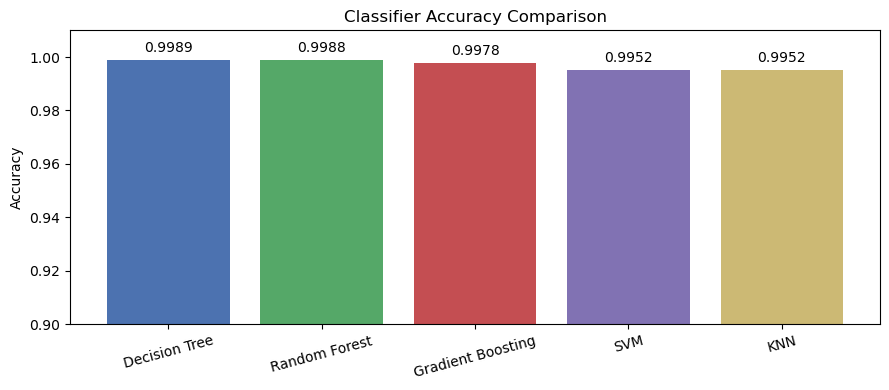

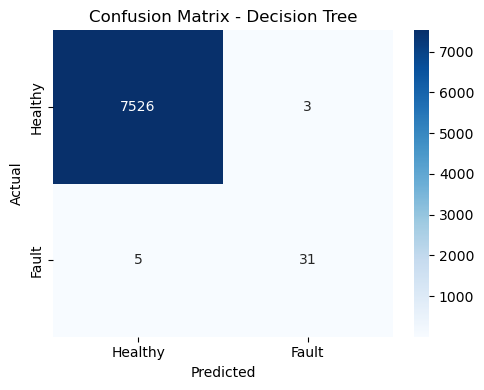

In [4]:
# Classification: compare five models and show the best result
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Load and clean train/test data
path = r"C:\Users\Kushal L\OneDrive\Desktop\KUSHALS FILES\major project"
train_df = pd.read_excel(path + "\\train.xlsx").drop_duplicates().dropna()
test_df = pd.read_excel(path + "\\test.xlsx").drop_duplicates().dropna()

# Smart dataset preview: show shape + a small sample instead of the full table
full_classification_df = pd.concat([train_df, test_df], ignore_index=True)
print(f"Train dataset shape: {train_df.shape[0]} rows, {train_df.shape[1]} columns")
print(f"Test dataset shape: {test_df.shape[0]} rows, {test_df.shape[1]} columns")
print(f"Combined dataset shape: {full_classification_df.shape[0]} rows, {full_classification_df.shape[1]} columns")
display(full_classification_df.head())

# Convert machine status into two classes: Healthy = 0, Fault = 1
status_map = {"Normal": 0, "Healthy": 0, "Warning": 1,
              "Maintenance Required": 1, "Fault": 1}
for df in [train_df, test_df]:
    df["Machine Status"] = df["Machine Status"].map(status_map)
    df["MRR"] = df["Feed Rate (mm/min)"] * df["Depth of Cut (mm)"] * df["Cutting Speed (m/min)"]
    df["Tool_Load"] = df["Feed Rate (mm/min)"] * df["Depth of Cut (mm)"]
    df["Power_Efficiency"] = df["MRR"] / df["Power Consumption (kW)"]

features = [
    "Spindle Speed (RPM)", "Feed Rate (mm/min)", "Cutting Speed (m/min)",
    "Depth of Cut (mm)", "Cutting Force (N)", "Temperature (C)",
    "Power Consumption (kW)", "Tool Wear (%)", "Surface Roughness (Ra)",
    "Vibration (mm/s)", "MRR", "Tool_Load", "Power_Efficiency"
]
X_train, y_train = train_df[features], train_df["Machine Status"]
X_test, y_test = test_df[features], test_df["Machine Status"]

# Train five classifiers and compare test accuracy
models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "SVM": SVC(random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5),
}
results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    accuracy = accuracy_score(y_test, model.predict(X_test))
    results.append((name, accuracy))
    print(f"{name}: {accuracy:.4f}")

best_name, best_accuracy = max(results, key=lambda item: item[1])
best_model = models[best_name]
y_pred = best_model.predict(X_test)
print(f"\nBest model: {best_name} ({best_accuracy:.4f})")
print(classification_report(y_test, y_pred))

# Figure 1: accuracy comparison
names, scores = zip(*results)
plt.figure(figsize=(9, 4))
plt.bar(names, scores, color=["#4C72B0", "#55A868", "#C44E52", "#8172B3", "#CCB974"])
plt.ylim(0.90, 1.01)
plt.ylabel("Accuracy")
plt.title("Classifier Accuracy Comparison")
plt.xticks(rotation=15)
for i, score in enumerate(scores):
    plt.text(i, score + 0.003, f"{score:.4f}", ha="center")
plt.tight_layout()
plt.show()

# Figure 2: confusion matrix for the best model
plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=["Healthy", "Fault"], yticklabels=["Healthy", "Fault"])
plt.title(f"Confusion Matrix - {best_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()


Decision Tree Train R2: 1.0000
Random Forest Train R2: 0.9694
Gradient Boosting Train R2: 0.8065

Best model: Decision Tree (1.0000)
MAE: 0.0
RMSE: 0.0

Predicted Regression Output Values:
Cutting Force (N): 484.65
Temperature (C): 57.51
Power Consumption (kW): 7.69
Tool Wear (%): 10.94
Surface Roughness (Ra): 0.883
Vibration (mm/s): 2.840


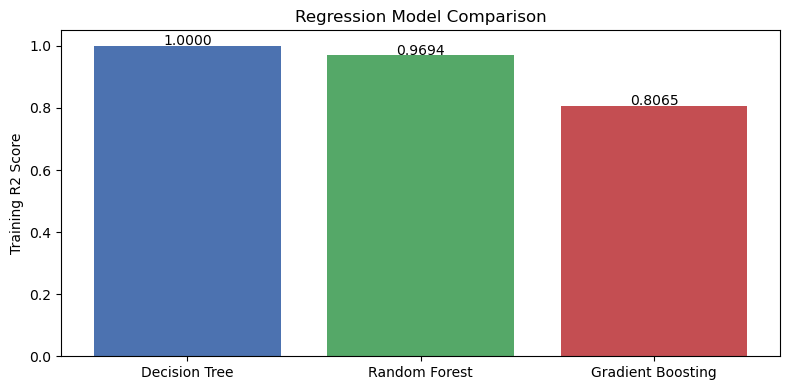

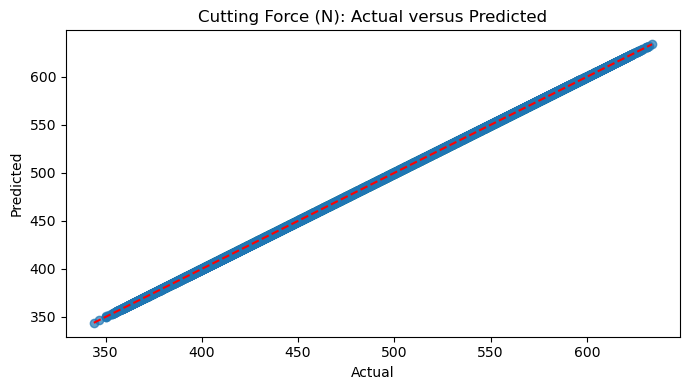

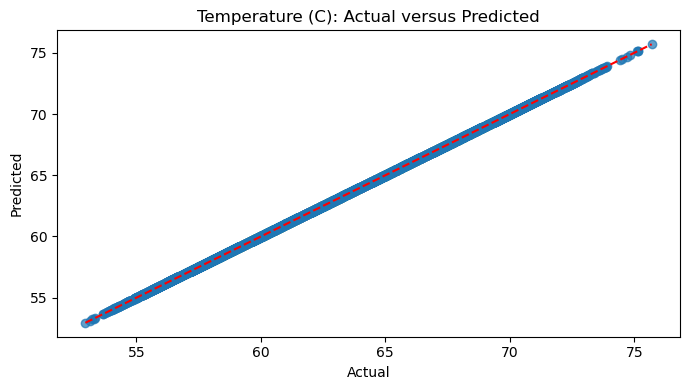

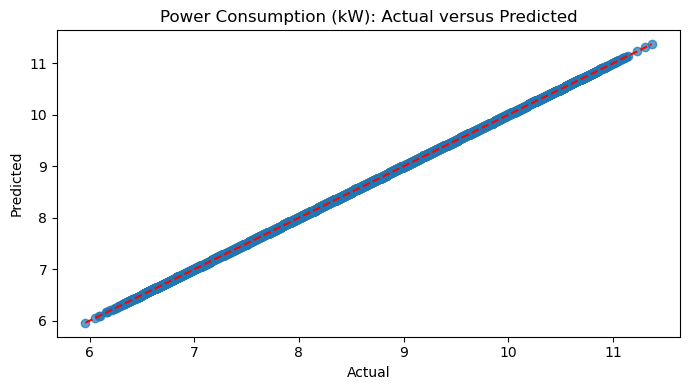

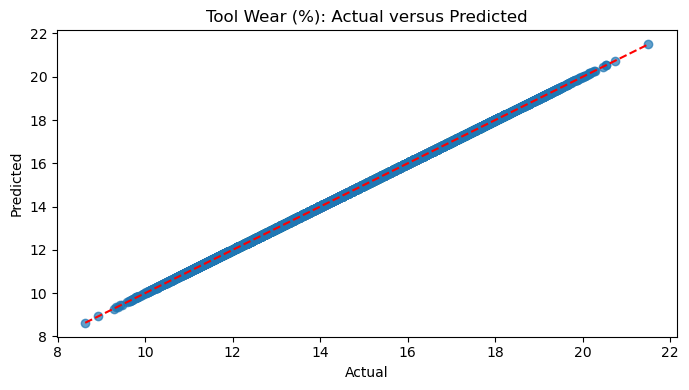

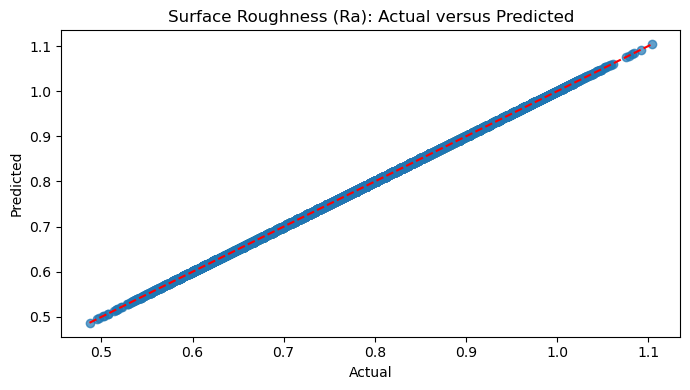

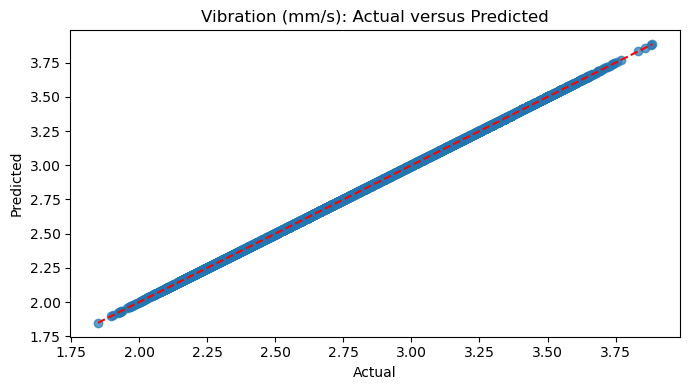

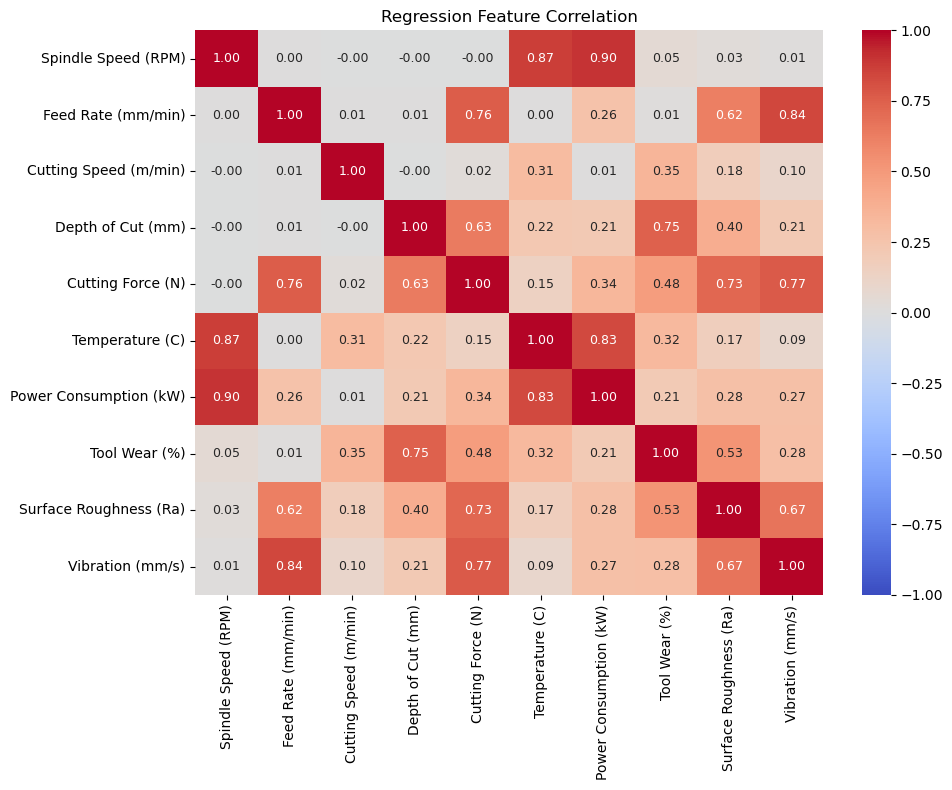

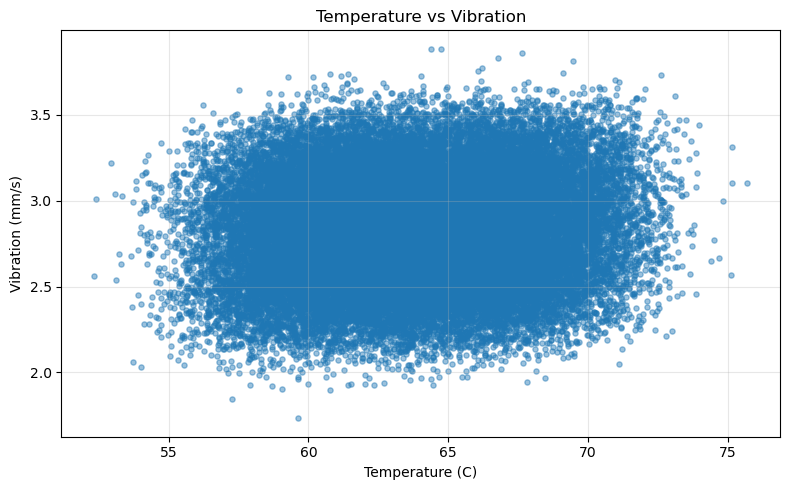

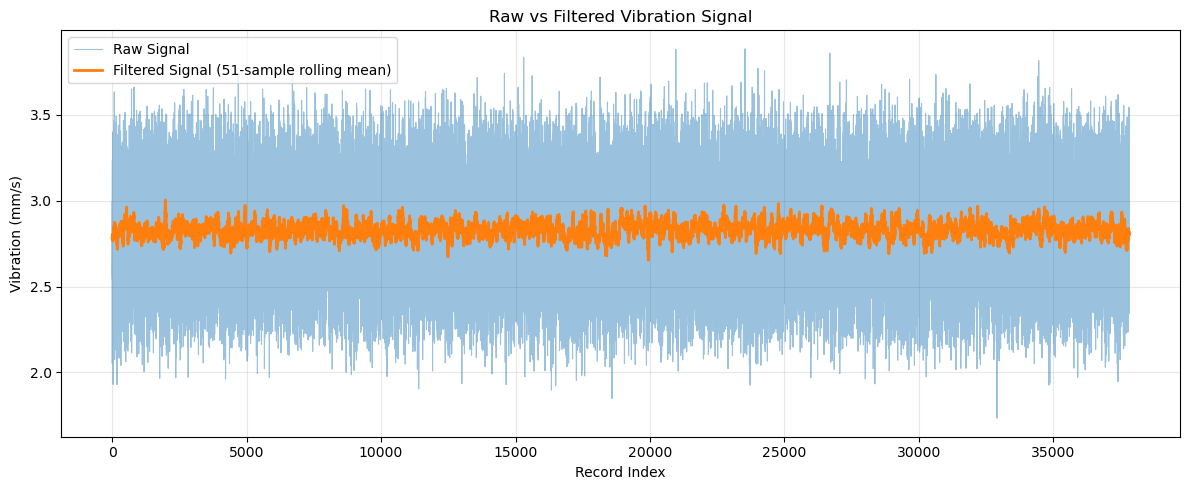

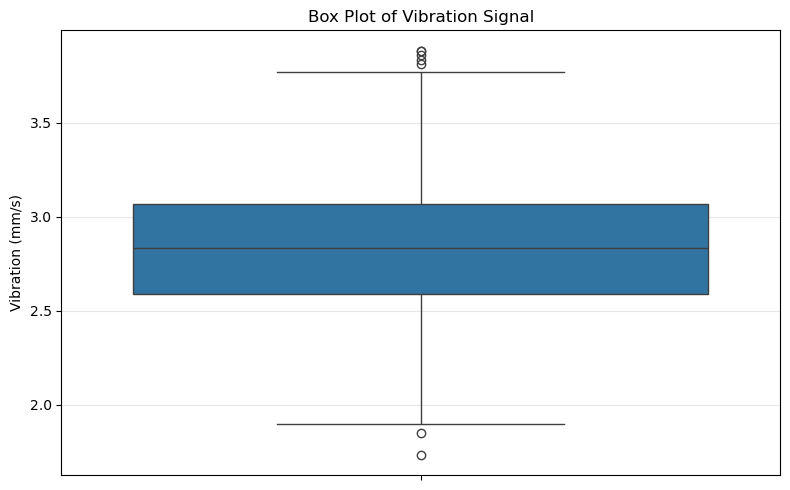

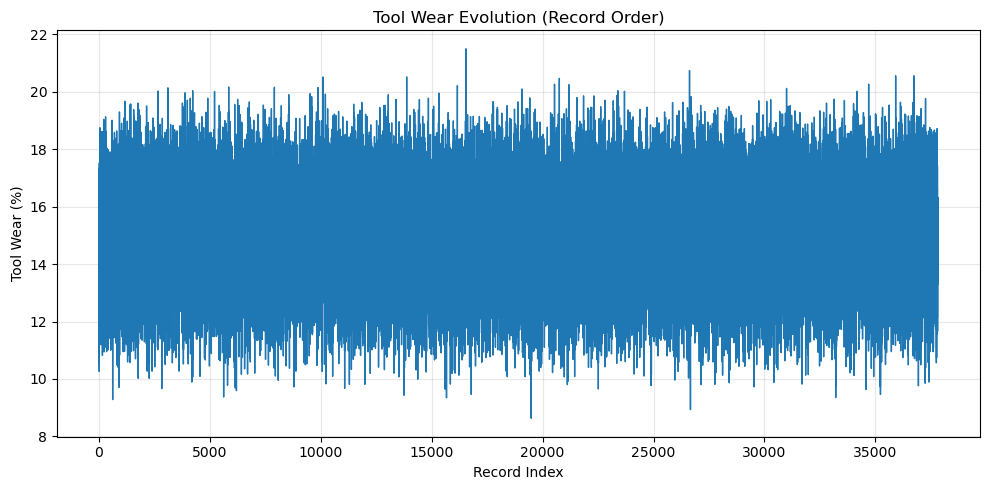

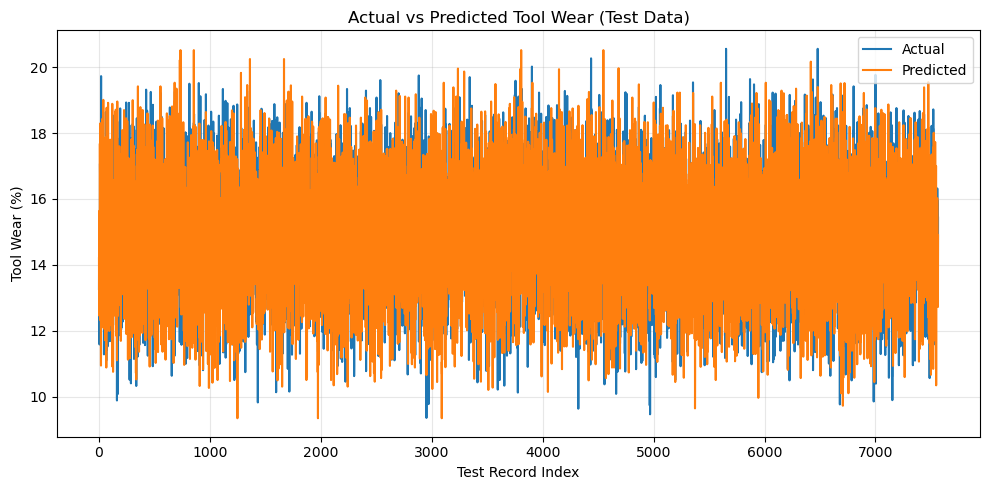

In [2]:
# Regression: compare three models and predict manually
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.multioutput import MultiOutputRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Load and clean training and test data
path = r"C:\Users\Kushal L\OneDrive\Desktop\KUSHALS FILES\major project"
train_df = pd.read_excel(path + "\\train.xlsx").drop_duplicates().dropna()
test_df = pd.read_excel(path + "\\test.xlsx").drop_duplicates().dropna()

input_features = [
    "Spindle Speed (RPM)", "Feed Rate (mm/min)",
    "Cutting Speed (m/min)", "Depth of Cut (mm)",
]
output_features = [
    "Cutting Force (N)", "Temperature (C)",
    "Power Consumption (kW)", "Tool Wear (%)",
    "Surface Roughness (Ra)", "Vibration (mm/s)",
]
X_regression = train_df[input_features]
y_regression = train_df[output_features].astype(float)

# Compare three regression algorithms using training data
models = {
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}
results = []
for name, base_model in models.items():
    model = MultiOutputRegressor(base_model)
    model.fit(X_regression, y_regression)
    train_pred = model.predict(X_regression)
    score = r2_score(y_regression, train_pred, multioutput="uniform_average")
    results.append((name, score, model, train_pred))
    print(f"{name} Train R2: {score:.4f}")

# Select the model with the highest training R2
best_name, best_r2, reg_model, train_pred = max(results, key=lambda item: item[1])
mae = mean_absolute_error(y_regression, train_pred, multioutput="uniform_average")
rmse = np.sqrt(mean_squared_error(y_regression, train_pred, multioutput="uniform_average"))
print(f"\nBest model: {best_name} ({best_r2:.4f})")
print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))

# Enter four values and predict six outputs
new_input = pd.DataFrame([{
    "Spindle Speed (RPM)": float(input("Spindle Speed (RPM): ")),
    "Feed Rate (mm/min)": float(input("Feed Rate (mm/min): ")),
    "Cutting Speed (m/min)": float(input("Cutting Speed (m/min): ")),
    "Depth of Cut (mm)": float(input("Depth of Cut (mm): ")),
}])
prediction = reg_model.predict(new_input)[0]

print("\nPredicted Regression Output Values:")
for name, value in zip(output_features, prediction):
    decimals = 3 if name in ["Surface Roughness (Ra)", "Vibration (mm/s)"] else 2
    print(f"{name}: {value:.{decimals}f}")

# Model comparison figure
model_names = [item[0] for item in results]
model_scores = [item[1] for item in results]
plt.figure(figsize=(8, 4))
plt.bar(model_names, model_scores, color=["#4C72B0", "#55A868", "#C44E52"])
plt.ylabel("Training R2 Score")
plt.title("Regression Model Comparison")
for i, score in enumerate(model_scores):
    plt.text(i, score + 0.002, f"{score:.4f}", ha="center")
plt.tight_layout()
plt.show()

# Actual versus predicted figures
for idx, target in enumerate(output_features):
    plt.figure(figsize=(7, 4))
    plt.scatter(y_regression[target], train_pred[:, idx], alpha=0.7)
    low = min(y_regression[target].min(), train_pred[:, idx].min())
    high = max(y_regression[target].max(), train_pred[:, idx].max())
    plt.plot([low, high], [low, high], "r--")
    plt.title(f"{target}: Actual versus Predicted")
    plt.xlabel("Actual")
    plt.ylabel("Predicted")
    plt.tight_layout()
    plt.show()

# Correlation heatmap
corr_matrix = train_df[input_features + output_features].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            annot_kws={"size": 9})
plt.title("Regression Feature Correlation")
plt.tight_layout()
plt.show()

# Requested vibration and tool-wear plots
required_plot_columns = ["Temperature (C)", "Vibration (mm/s)", "Tool Wear (%)"]
for dataset_name, dataset in (("train_df", train_df), ("test_df", test_df)):
    missing = [column for column in required_plot_columns if column not in dataset.columns]
    if missing:
        raise ValueError(f"{dataset_name} is missing plot columns: {missing}")

plot_df = pd.concat([train_df, test_df], ignore_index=True)

# 1. Temperature vs vibration
plt.figure(figsize=(8, 5))
plt.scatter(plot_df["Temperature (C)"], plot_df["Vibration (mm/s)"], alpha=0.45, s=14)
plt.title("Temperature vs Vibration")
plt.xlabel("Temperature (C)")
plt.ylabel("Vibration (mm/s)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 2. Raw vs rolling-mean filtered vibration
raw_vibration = pd.to_numeric(plot_df["Vibration (mm/s)"], errors="raise")
filtered_vibration = raw_vibration.rolling(window=51, center=True, min_periods=1).mean()
plt.figure(figsize=(12, 5))
plt.plot(raw_vibration.to_numpy(), label="Raw Signal", alpha=0.45, linewidth=0.8)
plt.plot(filtered_vibration.to_numpy(), label="Filtered Signal (51-sample rolling mean)", linewidth=2)
plt.title("Raw vs Filtered Vibration Signal")
plt.xlabel("Record Index")
plt.ylabel("Vibration (mm/s)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 3. Vibration signal distribution
plt.figure(figsize=(8, 5))
sns.boxplot(y=plot_df["Vibration (mm/s)"])
plt.title("Box Plot of Vibration Signal")
plt.ylabel("Vibration (mm/s)")
plt.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# 4. Tool-wear evolution in record order
plt.figure(figsize=(10, 5))
plt.plot(plot_df["Tool Wear (%)"].to_numpy(), linewidth=1)
plt.title("Tool Wear Evolution (Record Order)")
plt.xlabel("Record Index")
plt.ylabel("Tool Wear (%)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 5. Held-out actual vs predicted tool wear
wear_column = "Tool Wear (%)"
if "reg_model" not in globals() or "input_features" not in globals() or "output_features" not in globals():
    raise RuntimeError("Run the regression cell first so the fitted model and feature lists are available.")
if wear_column not in output_features:
    raise ValueError(f"The regression model does not include {wear_column!r} in output_features.")

actual_wear = pd.to_numeric(test_df[wear_column], errors="raise").to_numpy()
predicted_outputs = reg_model.predict(test_df[input_features])
wear_index = output_features.index(wear_column)
predicted_wear = predicted_outputs[:, wear_index]
if len(actual_wear) != len(predicted_wear):
    raise ValueError("Actual and predicted tool-wear values have different lengths.")

sample_index = np.arange(len(actual_wear))
plt.figure(figsize=(10, 5))
plt.plot(sample_index, actual_wear, label="Actual", linewidth=1.5)
plt.plot(sample_index, predicted_wear, label="Predicted", linewidth=1.5)
plt.title("Actual vs Predicted Tool Wear (Test Data)")
plt.xlabel("Test Record Index")
plt.ylabel("Tool Wear (%)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# Final Explanation: Classification and Regression

## Why are there two parts?

This CNC machine project solves two different machine-learning problems:

- **Classification** predicts a category: Is the machine **Healthy** or does it have a **Fault**?
- **Regression** predicts numerical values: What will the cutting force, temperature, power consumption, tool wear, surface roughness, and vibration be?

The two parts are separate because they have different target values and use different evaluation methods.

## Classification Part

The classification code uses the train data to learn patterns and the test data to check how well the models work on new data. The machine-status labels are converted into two classes:

- `0`: Healthy, including Normal
- `1`: Fault, including Warning, Maintenance Required, and Fault

### Classification algorithms

- **Decision Tree:** Splits the data using simple questions, such as whether a temperature or tool-wear value is above a limit. It is easy to understand but can overfit.
- **Random Forest:** Builds many decision trees and combines their results. It is usually more stable than one tree.
- **Gradient Boosting:** Builds trees one after another. Each new tree tries to correct the errors made by the previous trees.
- **SVM:** Finds the best boundary between the Healthy and Fault classes.
- **KNN:** Looks at the nearest training examples and predicts the class that appears most often nearby.

### Classification result

The models are compared using **accuracy**. In this dataset, the best classifier is the **Decision Tree**, with approximately **99.89% test accuracy**. The confusion matrix shows the number of correct and incorrect Healthy and Fault predictions.

## Regression Part

The regression code uses only the training data, as required for this project. Four machining inputs are entered manually:

- Spindle speed
- Feed rate
- Cutting speed
- Depth of cut

The model predicts six numerical outputs:

- Cutting force
- Temperature
- Power consumption
- Tool wear
- Surface roughness
- Vibration

`MultiOutputRegressor` allows one regression algorithm to predict all six output values.

### Regression algorithms

- **Decision Tree Regressor:** Splits the input values into regions and predicts a numerical average in each region.
- **Random Forest Regressor:** Combines predictions from many regression trees to produce a more stable result.
- **Gradient Boosting Regressor:** Builds trees step by step, with each tree improving the previous prediction.

### Regression result

The regressors are compared using training **R2 score**. R2 shows how much of the variation in the output values is explained by the model. The notebook also calculates:

- **MAE:** Average absolute prediction error. Lower is better.
- **RMSE:** Gives a larger penalty to bigger errors. Lower is better.

The model with the highest training R2 is selected for the manual prediction. A very high training score, especially a perfect score from a Decision Tree, can indicate overfitting. Therefore, training scores show how well the model learned the available data, but a separate test set would be needed to measure performance on unseen regression data.

## Difference Between Classification and Regression

| Classification | Regression |
|---|---|
| Predicts categories or labels | Predicts continuous numbers |
| Example: Healthy or Fault | Example: Temperature = 63.34 C |
| Uses classifiers | Uses regressors |
| Main metric: accuracy | Main metrics: R2, MAE, and RMSE |
| Output is a class | Output is one or more numerical values |

## Overall Project Use

Together, the two parts provide a complete CNC-machine analysis:

1. **Classification** gives a quick machine-health decision.
2. **Regression** estimates the machine's future operating values.
3. The figures help compare models and understand prediction quality.
4. Manual input allows a user to enter machining parameters and receive predicted outputs.
